# Google Trends: interés público en energías renovables (2016–2026)

**Estudiante:** Jhonny Benitez Caro · **Curso:** Electiva 2 y 3
**Asignatura/proyecto:** Python for Research – Data Processing Case Studies · **Caso de estudio 2**

## 1. Introducción y objetivo
Google Trends mide el interés de búsqueda relativo (0–100) de un término. En este trabajo se analiza el interés mundial
por **"solar energy"**, **"wind energy"** y **"hydropower"** durante los últimos 10 años.

**Objetivos**
1. Limpiar los datos y garantizar intervalos de tiempo consistentes.
2. Identificar y visualizar tendencias a lo largo del tiempo.
3. Detectar patrones estacionales.
4. Comparar el interés entre fuentes y entre regiones (países).
5. Resaltar anomalías (picos de interés).

**Datos:** descargados con `pytrends` (script `download_data.py`), búsqueda web mundial, resolución mensual.
Los tres términos se consultaron **en la misma petición**, por lo que comparten escala y son comparables entre sí.

> Nota metodológica: los valores son *relativos* (100 = máximo de popularidad en el periodo y región), no volúmenes absolutos.

## 2. Configuración y carga de datos

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import STL

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

DATA = Path("data")
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)
TERMS = ["solar energy", "wind energy", "hydropower"]
COLORS = {"solar energy": "#E69F00", "wind energy": "#0072B2", "hydropower": "#009E73"}

def savefig(name):
    plt.savefig(FIGS / f"{name}.png", bbox_inches="tight")

raw_time = pd.read_csv(DATA / "interest_over_time.csv")
raw_region = pd.read_csv(DATA / "interest_by_region.csv")
print("Serie temporal:", raw_time.shape, "| Regiones:", raw_region.shape)
raw_time.head()

Serie temporal: (121, 5) | Regiones: (250, 5)


,date,solar energy,wind energy,hydropower,isPartial
0,2016-11-01,33,14,5,False
1,2016-12-01,28,11,4,False
2,2017-01-01,32,12,4,False
3,2017-02-01,34,14,4,False
4,2017-03-01,33,14,5,False


## 3. Limpieza de datos
Se revisan: tipos de dato, valores faltantes, duplicados, observaciones parciales y regularidad de las fechas.

In [2]:
print(raw_time.dtypes, end="\n\n")
print("Valores nulos por columna:\n", raw_time.isna().sum(), end="\n\n")
print("Fechas duplicadas:", raw_time["date"].duplicated().sum())
print("Observaciones parciales (isPartial=True):", raw_time["isPartial"].sum())
raw_time[raw_time["isPartial"]]

date              str
solar energy    int64
wind energy     int64
hydropower      int64
isPartial        bool
dtype: object

Valores nulos por columna:
 date            0
solar energy    0
wind energy     0
hydropower      0
isPartial       0
dtype: int64

Fechas duplicadas: 0
Observaciones parciales (isPartial=True): 1


,date,solar energy,wind energy,hydropower,isPartial
120,2026-11-01,28,9,4,True


In [3]:
ts = raw_time.copy()
ts["date"] = pd.to_datetime(ts["date"], errors="coerce")

# 1) Quitar la observación parcial: el mes en curso está incompleto y sesgaría las tendencias.
ts = ts[~ts["isPartial"]].drop(columns="isPartial")

# 2) Fechas inválidas / duplicadas.
ts = ts.dropna(subset=["date"]).drop_duplicates(subset="date").set_index("date").sort_index()

# 3) Intervalos consistentes: reindexar a frecuencia mensual (inicio de mes) y localizar huecos.
full_index = pd.date_range(ts.index.min(), ts.index.max(), freq="MS")
missing_dates = full_index.difference(ts.index)
print(f"Meses esperados: {len(full_index)} | presentes: {len(ts)} | faltantes: {len(missing_dates)}")
ts = ts.reindex(full_index)
ts.index.name = "date"

# 4) Relleno de huecos (si los hubiera) por interpolación temporal; límite de 2 meses seguidos.
ts[TERMS] = ts[TERMS].interpolate(method="time", limit=2)
assert ts[TERMS].isna().sum().sum() == 0, "Quedan valores faltantes"

# 5) Validación de rango (el índice de Trends debe estar en [0, 100]).
assert ((ts[TERMS] >= 0) & (ts[TERMS] <= 100)).all().all()
print("Intervalo de tiempo uniforme:", ts.index.freqstr)
ts.describe().round(1)

Meses esperados: 120 | presentes: 120 | faltantes: 0
Intervalo de tiempo uniforme: MS


,solar energy,wind energy,hydropower
count,120.0,120.0,120.0
mean,35.1,13.4,5.6
std,14.2,5.5,3.2
min,22.0,7.0,3.0
25%,28.0,10.0,4.0
50%,30.5,12.0,5.0
75%,35.2,14.0,6.0
max,100.0,35.0,20.0


**Resultado de la limpieza:** la serie queda con frecuencia mensual regular (`MS`), sin nulos y sin duplicados, y se descarta
el último mes por ser parcial. Para las regiones se filtran los países sin datos.

In [4]:
reg = raw_region.rename(columns={"geoName": "country", "geoCode": "iso2"}).copy()
reg = reg.dropna(subset=["iso2"]).drop_duplicates("iso2")
reg[TERMS] = reg[TERMS].apply(pd.to_numeric, errors="coerce")
# Países con los tres valores en 0 = Google no devolvió suficiente volumen de búsqueda.
sin_datos = (reg[TERMS].sum(axis=1) == 0)
print(f"Países totales: {len(reg)} | sin datos suficientes: {sin_datos.sum()}")
reg = reg[~sin_datos].reset_index(drop=True)
print(f"Países usados en el análisis regional: {len(reg)}")
reg.head()

Países totales: 249 | sin datos suficientes: 28
Países usados en el análisis regional: 221


,country,iso2,solar energy,wind energy,hydropower
0,Afghanistan,AF,62,18,20
1,Albania,AL,47,16,37
2,Algeria,DZ,68,25,7
3,American Samoa,AS,61,25,14
4,Andorra,AD,77,23,0


## 4. Tendencias en el tiempo
### 4.1 Serie mensual y media móvil de 12 meses
La media móvil anual elimina la estacionalidad y deja ver la tendencia de fondo.

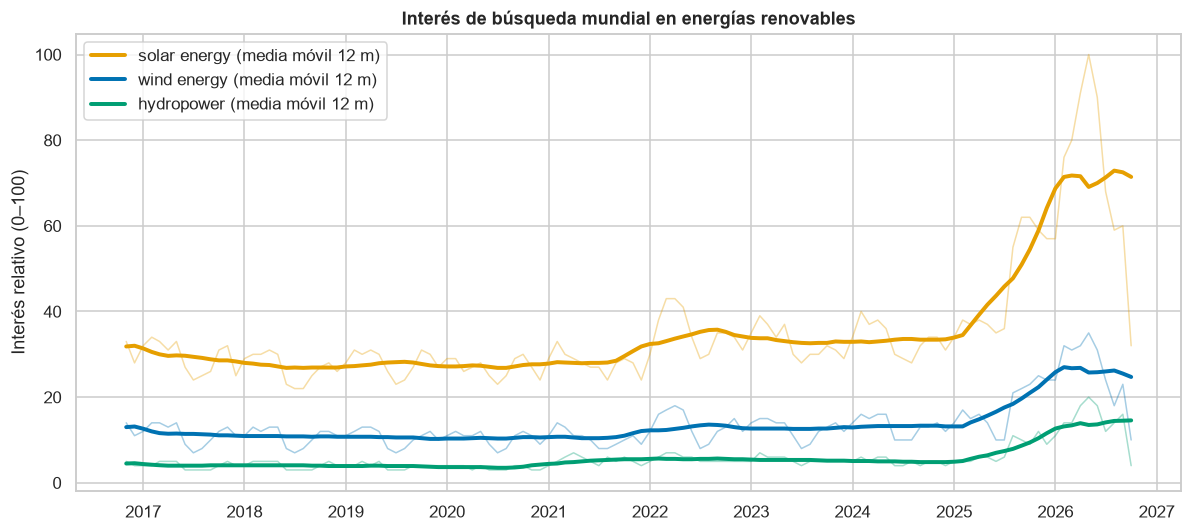

In [5]:
roll = ts[TERMS].rolling(12, center=True, min_periods=6).mean()

fig, ax = plt.subplots(figsize=(11, 5))
for t in TERMS:
    ax.plot(ts.index, ts[t], color=COLORS[t], alpha=.35, lw=1)
    ax.plot(roll.index, roll[t], color=COLORS[t], lw=2.6, label=f"{t} (media móvil 12 m)")
ax.set(title="Interés de búsqueda mundial en energías renovables", ylabel="Interés relativo (0–100)", xlabel="")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(frameon=True); plt.tight_layout(); savefig("01_tendencia_temporal"); plt.show()

### 4.2 Cuantificación de la tendencia (regresión lineal y variación interanual)

In [6]:
x = np.arange(len(ts))
rows = []
for t in TERMS:
    res = stats.linregress(x, ts[t].values)
    rows.append({
        "término": t,
        "media": ts[t].mean(),
        "pendiente (puntos/año)": res.slope * 12,
        "R²": res.rvalue ** 2,
        "p-valor": res.pvalue,
        "tendencia": "significativa" if res.pvalue < 0.05 else "no significativa",
    })
trend = pd.DataFrame(rows).set_index("término").round(3)
trend

,media,pendiente (puntos/año),R²,p-valor,tendencia
término,,,,,
solar energy,35.117,3.026,0.380,0.0,significativa
wind energy,13.417,1.073,0.323,0.0,significativa
hydropower,5.650,0.676,0.370,0.0,significativa


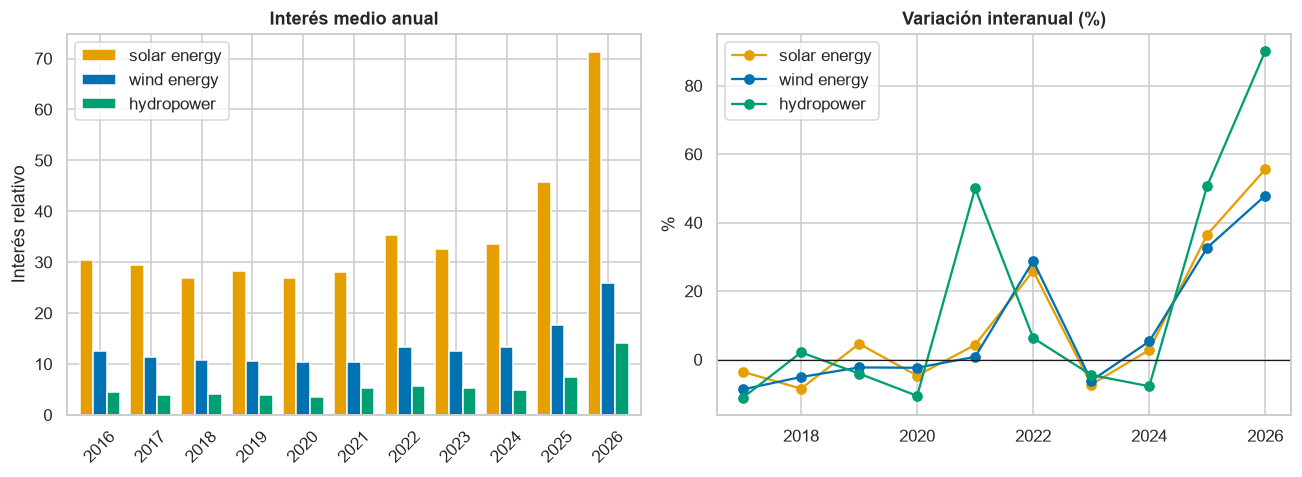

,solar energy,wind energy,hydropower
date,,,
2016,NaN,NaN,NaN
2017,-3.6,-8.7,-11.1
2018,-8.5,-5.1,2.1
2019,4.6,-2.3,-4.1
2020,-4.7,-2.4,-10.6
2021,4.3,0.8,50.0
2022,25.9,28.8,6.3
2023,-7.3,-6.2,-4.5
2024,2.8,5.3,-7.8


In [7]:
annual = ts[TERMS].groupby(ts.index.year).mean()
yoy = annual.pct_change().mul(100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
annual.plot(kind="bar", ax=axes[0], color=[COLORS[t] for t in TERMS], width=.8)
axes[0].set(title="Interés medio anual", xlabel="", ylabel="Interés relativo")
axes[0].legend(title=""); axes[0].tick_params(axis="x", rotation=45)

yoy.iloc[1:].plot(ax=axes[1], marker="o", color=[COLORS[t] for t in TERMS])
axes[1].axhline(0, color="k", lw=.8)
axes[1].set(title="Variación interanual (%)", xlabel="", ylabel="%"); axes[1].legend(title="")
plt.tight_layout(); savefig("02_media_anual_yoy"); plt.show()
yoy

## 5. Estacionalidad
Se descompone cada serie con **STL** (tendencia + estacionalidad + residuo) y se calcula la *fuerza estacional*
$F_s = \max(0,\; 1 - \mathrm{Var}(R)/\mathrm{Var}(S+R))$ (Hyndman & Athanasopoulos).

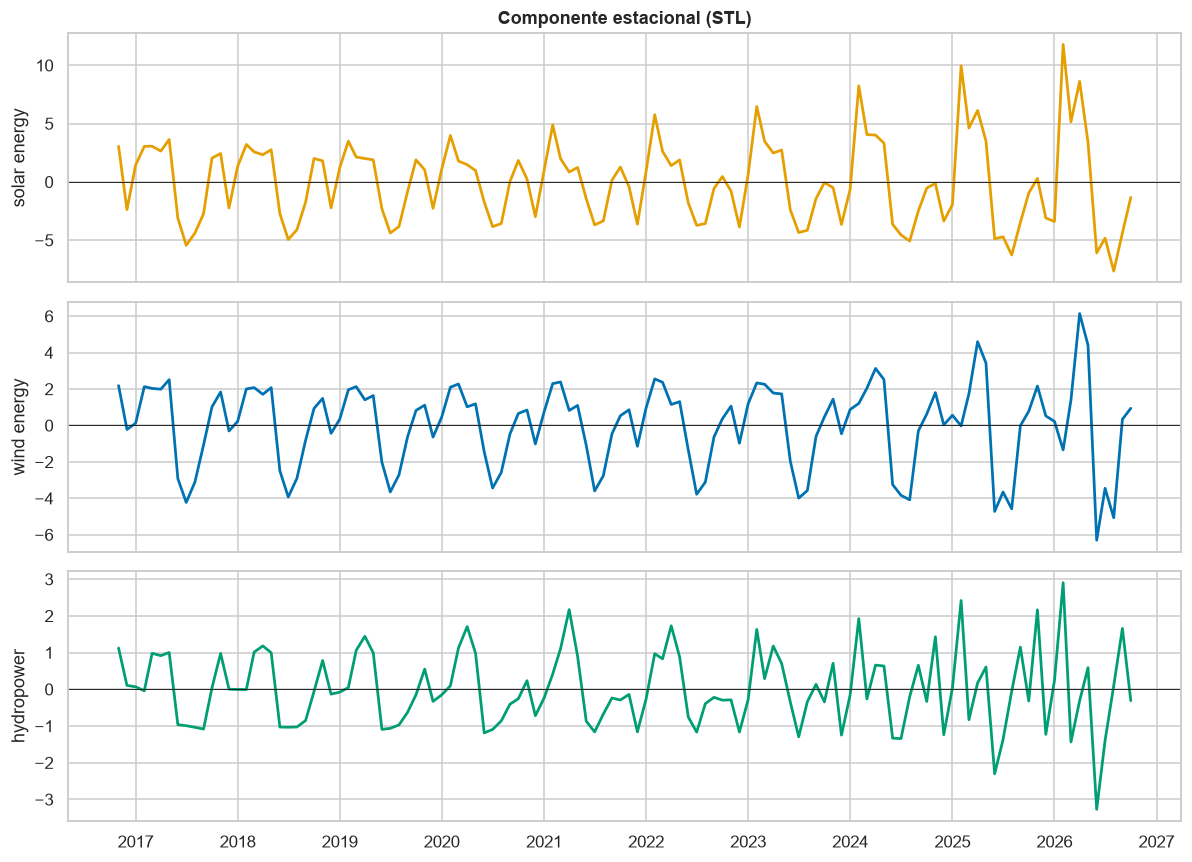

,fuerza estacional (0–1)
solar energy,0.236
wind energy,0.310
hydropower,0.023


In [8]:
stl = {t: STL(ts[t], period=12, robust=True).fit() for t in TERMS}

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, t in zip(axes, TERMS):
    ax.plot(stl[t].seasonal, color=COLORS[t], lw=1.8); ax.axhline(0, color="k", lw=.6)
    ax.set_ylabel(t)
axes[0].set_title("Componente estacional (STL)")
plt.tight_layout(); savefig("03_estacionalidad_stl"); plt.show()

strength = {t: max(0, 1 - stl[t].resid.var() / (stl[t].seasonal + stl[t].resid).var()) for t in TERMS}
pd.Series(strength, name="fuerza estacional (0–1)").round(3).to_frame()

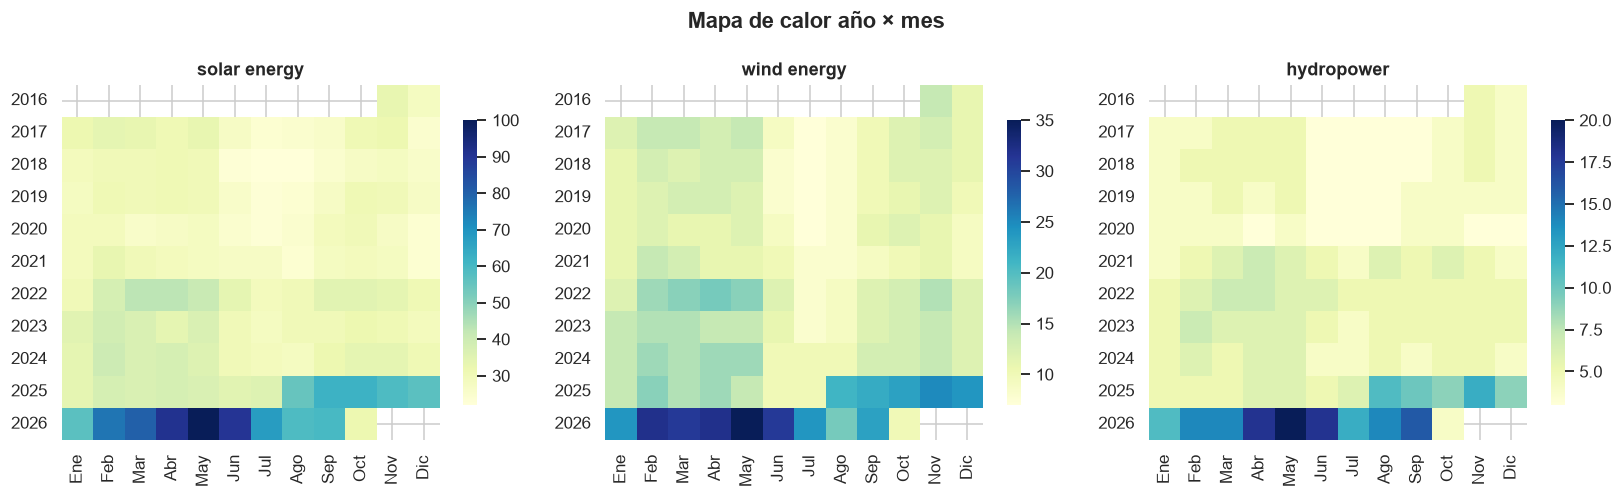

Mes pico: {'solar energy': 'May', 'wind energy': 'Feb', 'hydropower': 'May'}
Mes valle: {'solar energy': 'Dic', 'wind energy': 'Jul', 'hydropower': 'Dic'}


,solar energy,wind energy,hydropower
Ene,96.0,99.9,90.3
Feb,110.5,120.0,106.2
Mar,109.1,116.3,109.7
Abr,111.9,117.0,118.6
May,113.9,117.8,122.1
Jun,98.8,88.0,97.3
Jul,88.0,71.6,83.2
Ago,91.7,79.8,102.7
Sep,100.8,98.4,104.4
Oct,97.7,96.1,88.5


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, t in zip(axes, TERMS):
    pv = ts[t].groupby([ts.index.year, ts.index.month]).mean().unstack()
    pv.columns = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
    sns.heatmap(pv, ax=ax, cmap="YlGnBu", cbar_kws={"shrink": .8})
    ax.set(title=t, ylabel="", xlabel="")
fig.suptitle("Mapa de calor año × mes", fontweight="bold"); plt.tight_layout()
savefig("04_heatmap_anio_mes"); plt.show()

# Mes de mayor y menor interés (perfil estacional medio, base 100 = media anual)
perfil = ts[TERMS].groupby(ts.index.month).mean()
perfil = perfil.div(perfil.mean()).mul(100).round(1)
perfil.index = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
print("Mes pico:", perfil.idxmax().to_dict()); print("Mes valle:", perfil.idxmin().to_dict())
perfil

## 6. Anomalías y picos de interés
Se compara cada mes con la **mediana móvil centrada de 13 meses** (que absorbe tendencia y estacionalidad anual) y se marca
como anomalía todo mes con |z-score robusto| > 3.5, calculado con la mediana y el MAD (resistentes a los propios picos).
Se probó antes el residuo STL, pero un cambio de nivel en 2025–26 hacía que casi toda la última parte de la serie
apareciera como "anómala" (79 meses marcados); la mediana móvil separa mejor los picos puntuales.

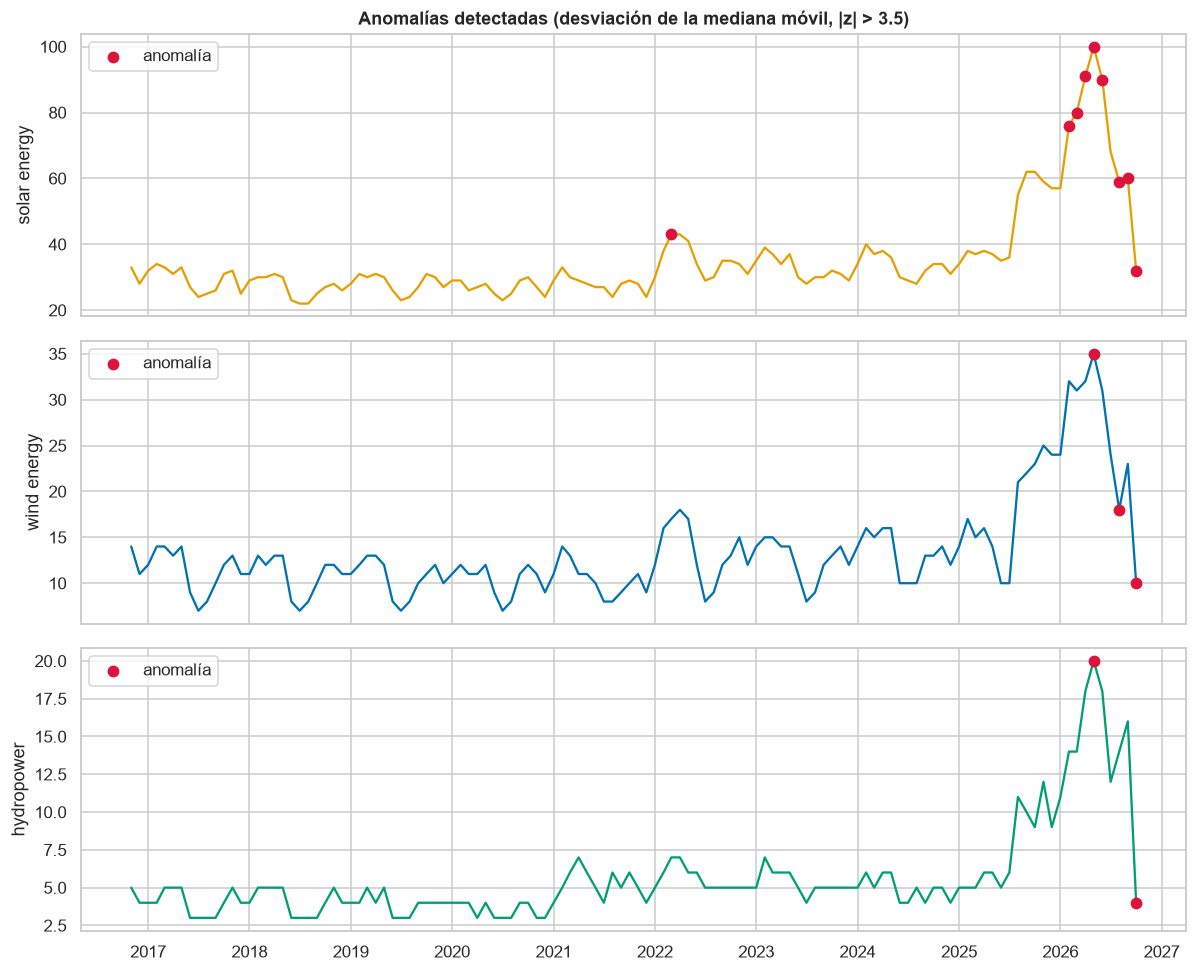

,término,mes,interés,z robusto
0,solar energy,2022-03,43,4.4
1,solar energy,2026-02,76,4.7
2,solar energy,2026-03,80,6.1
3,solar energy,2026-04,91,9.8
4,solar energy,2026-05,100,12.1
5,solar energy,2026-06,90,7.4
6,solar energy,2026-08,59,-5.7
7,solar energy,2026-09,60,-4.7
8,solar energy,2026-10,32,-12.1
9,wind energy,2026-05,35,4.0


In [10]:
anom_rows = []
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, t in zip(axes, TERMS):
    base = ts[t].rolling(13, center=True, min_periods=7).median()
    r = ts[t] - base
    mad = (r - r.median()).abs().median()
    z = 0.6745 * (r - r.median()) / mad
    flag = z.abs() > 3.5
    ax.plot(ts.index, ts[t], color=COLORS[t], lw=1.5)
    ax.scatter(ts.index[flag], ts[t][flag], color="crimson", zorder=3, s=45, label="anomalía")
    ax.set_ylabel(t); ax.legend(loc="upper left")
    for d in ts.index[flag]:
        anom_rows.append({"término": t, "mes": d.strftime("%Y-%m"), "interés": ts.at[d, t], "z robusto": round(z[d], 1)})
axes[0].set_title("Anomalías detectadas (desviación de la mediana móvil, |z| > 3.5)")
plt.tight_layout(); savefig("05_anomalias"); plt.show()
anomalies = pd.DataFrame(anom_rows)
anomalies if len(anomalies) else "Sin anomalías con el umbral elegido"

In [11]:
# Mayores picos absolutos de cada término
for t in TERMS:
    top = ts[t].nlargest(3)
    print(f"{t:13s}", ", ".join(f"{d:%Y-%m} ({v:.0f})" for d, v in top.items()))

solar energy  2026-05 (100), 2026-04 (91), 2026-06 (90)
wind energy   2026-05 (35), 2026-02 (32), 2026-04 (32)
hydropower    2026-05 (20), 2026-04 (18), 2026-06 (18)


**Interpretación.** Los picos suelen asociarse a eventos mediáticos, cumbres climáticas, crisis energéticas o a
cambios en la forma en que Google mide/clasifica los datos (Google actualiza su sistema de muestreo). Conviene
interpretarlos como *hipótesis* a contrastar con noticias de cada fecha, no como causas demostradas.

## 7. Comparación entre fuentes de energía
### 7.1 Correlación entre series
Correlación de Pearson sobre la serie sin tendencia (primeras diferencias) para evitar correlaciones espurias.

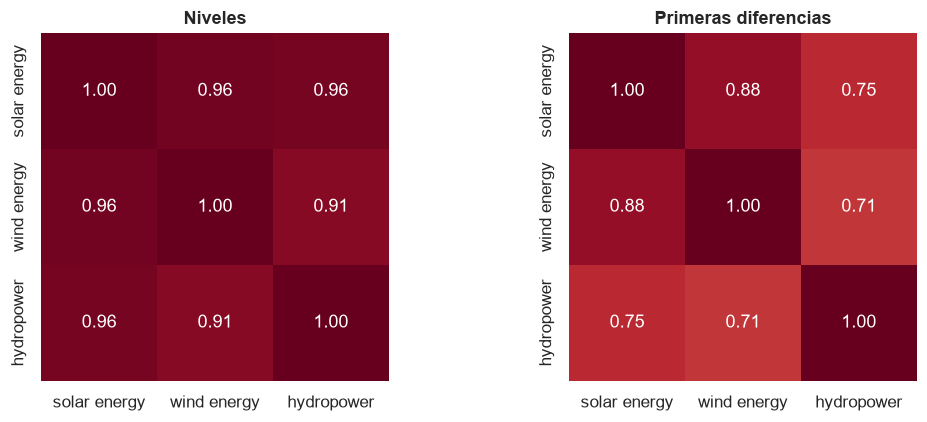

In [12]:
corr_levels = ts[TERMS].corr()
corr_diff = ts[TERMS].diff().dropna().corr()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, c, title in zip(axes, [corr_levels, corr_diff], ["Niveles", "Primeras diferencias"]):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True, cbar=False)
    ax.set_title(title)
plt.tight_layout(); savefig("06_correlaciones"); plt.show()

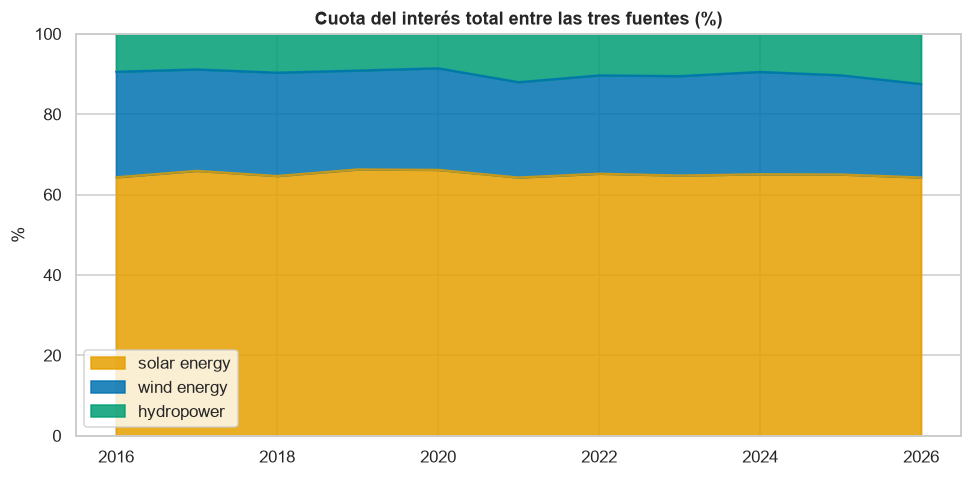

,solar energy,wind energy,hydropower
date,,,
2016,64.3,26.3,9.5
2017,65.9,25.2,8.9
2018,64.6,25.7,9.7
2019,66.2,24.6,9.2
2020,66.1,25.3,8.6
2021,64.2,23.7,12.0
2022,65.2,24.5,10.4
2023,64.7,24.7,10.5
2024,65.0,25.5,9.5


In [13]:
share = ts[TERMS].div(ts[TERMS].sum(axis=1), axis=0).mul(100)
share_year = share.groupby(share.index.year).mean()
ax = share_year.plot(kind="area", stacked=True, figsize=(9, 4.5), color=[COLORS[t] for t in TERMS], alpha=.85)
ax.set(title="Cuota del interés total entre las tres fuentes (%)", xlabel="", ylabel="%", ylim=(0, 100))
ax.legend(loc="lower left", frameon=True); plt.tight_layout(); savefig("07_cuota_interes"); plt.show()
share_year.round(1)

## 8. Comparación regional
Cada columna indica el interés relativo **dentro del país** (100 = el término más buscado en ese país entre los tres).
No es comparable en volumen absoluto entre países, sino en *composición* del interés.

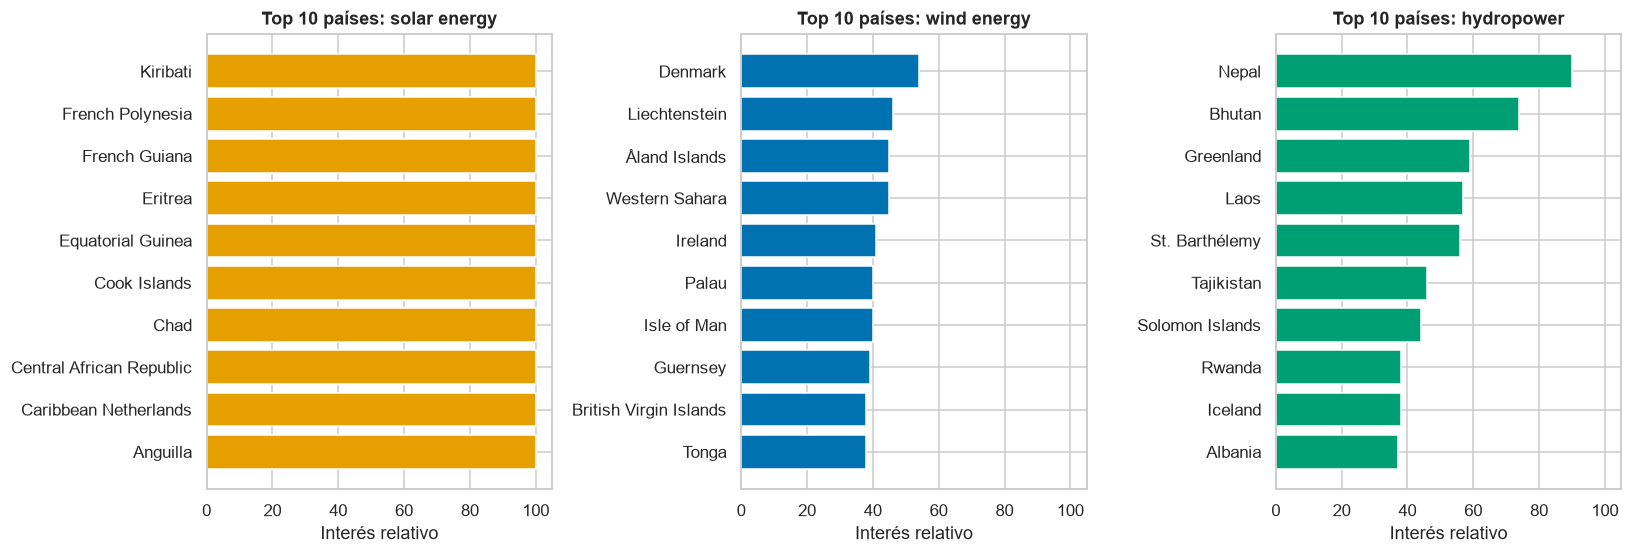

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharex=True)
for ax, t in zip(axes, TERMS):
    top = reg.nlargest(10, t).sort_values(t)
    ax.barh(top["country"], top[t], color=COLORS[t])
    ax.set_title(f"Top 10 países: {t}"); ax.set_xlabel("Interés relativo")
plt.tight_layout(); savefig("08_top_paises"); plt.show()

dominante
solar energy    213
hydropower        7
wind energy       1



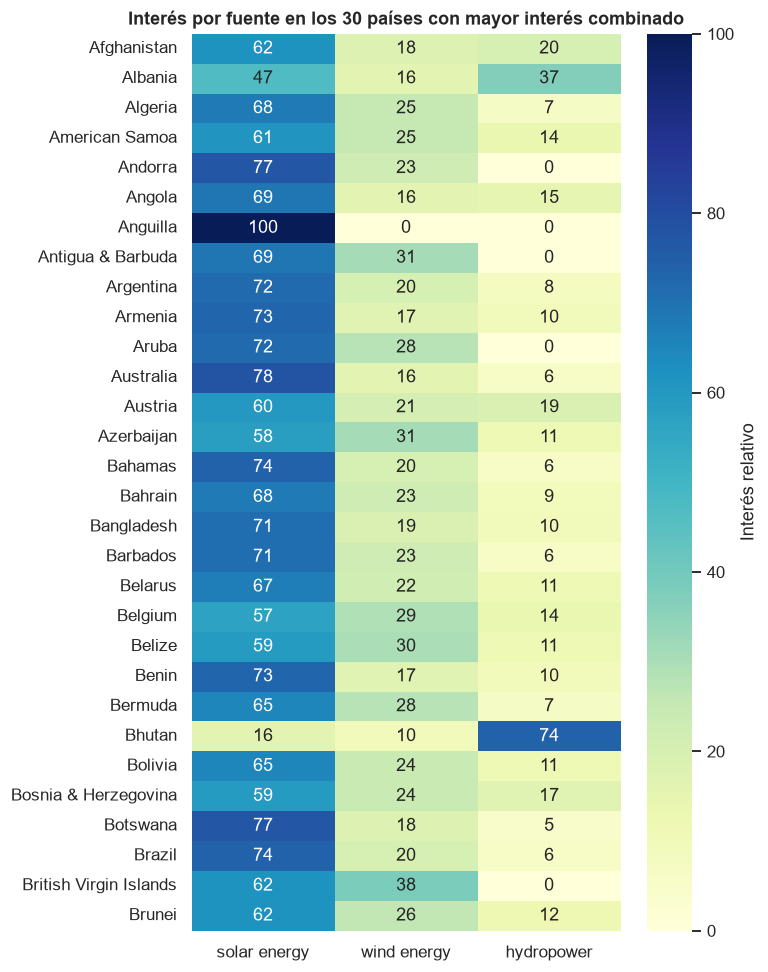

In [15]:
reg["dominante"] = reg[TERMS].idxmax(axis=1)
print(reg["dominante"].value_counts().to_string(), end="\n\n")

# Países con mayor interés combinado: heatmap país × fuente
reg["total"] = reg[TERMS].sum(axis=1)
top30 = reg.nlargest(30, "total").set_index("country")[TERMS]
plt.figure(figsize=(7, 9))
sns.heatmap(top30, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "Interés relativo"})
plt.title("Interés por fuente en los 30 países con mayor interés combinado"); plt.ylabel("")
plt.tight_layout(); savefig("09_heatmap_paises"); plt.show()

In [16]:
# Mapa mundial coroplético (ISO-2 -> ISO-3 con pycountry si está disponible; si no, se omite)
try:
    import plotly.express as px, pycountry
    def iso3(c):
        try: return pycountry.countries.get(alpha_2=c).alpha_3
        except Exception: return None
    reg["iso3"] = reg["iso2"].map(iso3)
    for t in TERMS:
        fig = px.choropleth(reg.dropna(subset=["iso3"]), locations="iso3", color=t, hover_name="country",
                            color_continuous_scale="YlGnBu", title=f"Interés relativo: {t}")
        fig.update_layout(margin=dict(l=0, r=0, t=40, b=0)); fig.show()
except ImportError:
    print("plotly/pycountry no instalados: se omiten los mapas (pip install plotly pycountry).")

In [17]:
# Estadísticos regionales y diferencias entre fuentes
print(reg[TERMS].describe().round(1), end="\n\n")
h, p = stats.kruskal(*[reg[t] for t in TERMS])
print(f"Kruskal-Wallis entre las tres fuentes: H={h:.1f}, p={p:.2e}")
rho = reg[TERMS].corr(method="spearman").round(2)
rho

       solar energy  wind energy  hydropower
count         221.0        221.0       221.0
mean           66.2         21.2        12.6
std            13.5          9.1        12.5
min             8.0          0.0         0.0
25%            60.0         17.0         6.0
50%            65.0         22.0        10.0
75%            72.0         25.0        16.0
max           100.0         54.0        90.0

Kruskal-Wallis entre las tres fuentes: H=465.8, p=7.13e-102


,solar energy,wind energy,hydropower
solar energy,1.00,-0.39,-0.72
wind energy,-0.39,1.00,-0.17
hydropower,-0.72,-0.17,1.00


## 9. Conclusiones
1. **Solar domina el interés público.** Media de 35 puntos frente a 13 (eólica) y 5.6 (hidroeléctrica). Su cuota del interés total se mantiene casi constante, en torno al 65 % (§7), con eólica ≈ 25 % e hidroeléctrica ≈ 10 %. Solo en 2026 hidroeléctrica sube a ≈ 12.5 %.
2. **Tendencia.** La regresión lineal es significativa para los tres términos (p < 0.001): +3.0, +1.1 y +0.7 puntos/año (R² ≈ 0.32–0.38). Pero el gráfico anual (§4.2) muestra que 2016–2024 fue **estable** (variaciones interanuales pequeñas, con un repunte en 2022) y que el crecimiento se concentra en **2025–2026** (+36 % y +56 % en solar). La pendiente lineal, por tanto, resume un salto reciente más que un aumento gradual.
3. **Estacionalidad.** Es moderada en solar (fuerza 0.24) y eólica (0.31) y casi nula en hidroeléctrica (0.02). El interés alcanza su máximo en **febrero–mayo** (solar y eólica ≈ +10–20 % sobre la media) y su mínimo en **julio–diciembre** (eólica en julio, solar en diciembre), coherente con el calendario académico y de noticias del hemisferio norte.
4. **Anomalías.** Hay un pico claro en **febrero–junio de 2026** (solar llega a 100 en mayo, eólica 35, hidroeléctrica 20) y una caída brusca en **octubre de 2026** en los tres términos. Esa caída simultánea sugiere un cambio en el muestreo o la clasificación de Google más que un cambio real en el interés. También destaca solar en marzo de 2022 (43), compatible con la crisis energética de ese año.
5. **Regiones.** Solar es el término dominante en 213 de 221 países; hidroeléctrica lo es en 7 y eólica en 1. Las diferencias entre fuentes son estadísticamente significativas (Kruskal-Wallis, p ≈ 1e-102). A nivel de país, el interés por solar se correlaciona negativamente con el de hidroeléctrica (ρ de Spearman = −0.72): donde la hidroeléctrica es relevante, la composición del interés se desplaza lejos de la solar.

### Limitaciones
- Google Trends es relativo y muestreado: ejecuciones en días distintos pueden dar cifras ligeramente diferentes.
- Buscar un término no implica apoyo ni conocimiento; el idioma de la búsqueda sesga el resultado (aquí, términos en inglés).
- Los países con bajo volumen de búsqueda pueden tener valores ruidosos.

### Reproducibilidad
```
pip install -r requirements.txt
python download_data.py        # opcional: ya se incluyen los CSV en data/
jupyter lab Google_Trends_Renewables.ipynb
```